<div class="alert alert-block alert-info">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Hola Alejandro, soy Santiago y hoy reviso tu proyecto. Guía rápida de colores: por favor no muevas, edites ni elimines mis comentarios. ¡Empecemos! 🚀
</div>

<div class="alert alert-block alert-success">Verde: algo está bien hecho.</div>
<div class="alert alert-block alert-warning">Amarillo: tip o recomendación, no bloquea la aprobación.</div>
<div class="alert alert-block alert-danger">Rojo: necesita corrección antes de aprobar.</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

**Resumen general:** muy buen trabajo técnico: la limpieza, el MAR, la agregación con `left` + `fillna(0)`, los histogramas con insights, el IQR y las segmentaciones están **bien resueltos** y el notebook corre sin errores en el código del análisis. Hay **dos puntos que necesitan corrección antes de aprobar**:

1. **El diagnóstico oficial de sentinels (sección 2.2) está incompleto:** solo menciona `city` y no incluye el `-999` de `age` ni cuántas filas afecta cada sentinel.
2. **El insight ejecutivo (Paso 7) tiene cifras incorrectas** (por ejemplo, dice que hay 565 filas con `?` sobre "5,000 registros") y afirmaciones sin cálculo que las respalde. Cada error está detallado en su celda.

El resto son advertencias (amarillo): el diagnóstico de nulos (2.1) recomienda "imputar con 0" y luego la sección 3.2 concluye lo contrario, textos de plantilla sin borrar, `np.nan` en lugar de `pd.NA`, la celda de GitHub (el link está en una celda de **código** y da `SyntaxError`) y que el notebook no está ejecutado de principio a fin (los números de ejecución empiezan en 18, hay repetidos y desordenados): al terminar haz **Kernel → Restart Kernel & Run All Cells**.
</div>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Tip: `numpy` (`np`) se usa más adelante en tres celdas (se importa dentro de una celda de limpieza). Es mejor importarlo aquí arriba junto con las demás librerías (`import numpy as np`).
</div>

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Carga correcta de los tres archivos, incluido `users_latam.csv`.
</div>

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Formas correctas: plans (2, 8), users (4000, 8), usage (40000, 6).
</div>

In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Buena inspección de estructura con `.info()` en los tres DataFrames; se ve que `usage.date` tiene 39,950 no nulos y que `city` y `churn_date` tienen nulos.
</div>

---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print()
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print()
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Nulos y proporciones calculados correctamente para `users` y `usage`.
</div>

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- En la tabla users, los valores faltantes se concentran en city (11.7%) y churn_date (88.3%), mientras que en usage se ubican en date (0.1%), duration (55.0%) y length (44.7%).
- Para el tratamiento, en users se estandariza city convirtiendo los ? a nulos para no perder registros, mientras que en churn_date la ausencia de fecha se ignora y se conserva intacta por indicar que el usuario sigue activo.
- Por su parte, en usage, los 50 registros sin fecha en date se ignoran (dejándolos nulos) para no perder el volumen de consumo real que aportan a los usuarios, y los vacíos en duration y length se conservan como nulos porque un mensaje no dura minutos y una llamada no tiene caracteres, evitando así alterar los promedios de cada canal.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Las cifras son correctas (11.7%, 88.3%, 0.1%, 55%, 44.7%), pero **algunas acciones se contradicen con lo que haces después**:
- `duration` y `length`: dices "imputar con 0", pero en la sección 3.2 tú mismo concluyes que **no se deben imputar con ceros** porque son nulos que dependen de `type` (estructurales). Ajusta aquí la acción: "conservar los nulos".
- `city`: dices "imputar/rellenar", pero en 3.1 la dejas como nulo. Aclara cuál es la decisión final.
- `date`: dices "eliminar", pero en la limpieza no se eliminan. Aclara si se eliminarán o se conservan.
- Borra las preguntas de la plantilla ("¿Qué columnas tienen valores faltantes...", "Indica qué harías...") y deja solo tu diagnóstico.
</div>

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.

El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

El `describe()` muestra claramente el problema de `age`: mínimo -999 y media 33.74 contra mediana 47.
</div>

- La columna `user_id` tiene un comportamiento normal con identificadores que van del 10,000 al 13,999.
- La columna `age` contiene un sentinel con valor de -999 que distorsiona la desviacion estandar y la media de 55 registros (1.4%). Estos valores se deben reemplazar por la mediana calculada sin el -999.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Buen hallazgo, pero el `-999` no es un outlier: es un **sentinel** (un valor que el sistema usa para decir "edad no registrada"). Completa aquí cuántas filas afecta (**55 de 4,000 = 1.4%**) y qué harás (reemplazarlo por la mediana calculada sin el `-999`). Esto también debe quedar en el diagnóstico oficial de la sección 2.2 (ver comentario más abajo).
</div>

In [13]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` tienen un comportamiento normal con identificadores continuos.
- La columna 'duration' muestran las llamadas con una mediana de 3.5 minutos y un maximo de 120 minutos.
- La columa 'length' presenta un outlier de 1,490 caracteres de un mensaje, y con un Q3 de 64 caracteres.

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Bien: identificas los máximos de `duration` (120 min) y `length` (1,490 caracteres), muy por encima de sus medianas.
</div>

In [14]:
# explorar columnas categóricas de users
for col in ['city', 'plan']:
    display(users[col].value_counts(dropna=False))

Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Basico     2595
Premium    1405
Name: plan, dtype: int64

- La columna `city` aparece el valor "?" 96 veces y 469 valores nulos.
- La columna `plan` tiene todos los datos completos.

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Correcto: `value_counts(dropna=False)` deja ver el sentinel `?` (96 filas) además de los 469 nulos.
</div>

In [15]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` muestra 22,092 filas de texto y 17,908 filas de llamadas, datos completos.


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Correcto: `text` 22,092 y `call` 17,908, sin nulos ni categorías raras.
</div>

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels? En la columna 'city' del archivo 'users'.
- ¿Qué acción tomarías? Reemplazar directamente el centinela '?' y los valores NaN existentes por 'Unknown' :
  users['city'] = users['city'].replace('?', np.nan).fillna('Unknown')

- Se encontraron sentinels en dos columnas del archivo 'users', en [age] se encuentra el valor -999 en 55 filas, las cuales representan un 1.4% del total, por lo que se debe de reemplazar por la mediana calculada sin contar los -999. En [city] se encontró el sentinel con el valor '?' en 96 filas (2.4%), la acción a realizar es convertirlo a nulo.
- En [duration] y [length] se observan valores muy por encima de la mediana, como llamadas de 120 minutos y mensajes de 1,490 caracteres. Eso no quiere decir que sean errores automáticos, se deberían de revisar como posibles outliers porque aunque sean muy poco comunes, sí es técnicamente posible.

<div class="alert alert-block alert-danger">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

**Bloqueante: el diagnóstico oficial de sentinels está incompleto.** Debe incluir:
1. **`age`**: sentinel `-999` (**55 filas, 1.4%**) y la acción (reemplazar por la mediana calculada **sin** contar los `-999`). Hoy solo se menciona en la celda de arriba, y no en este bloque.
2. **`city`**: sentinel `?` (**96 filas, 2.4%**) **más** los 469 nulos. La acción debe coincidir con tu limpieza: pasar `?` a nulo (en 3.1 lo haces así; aquí dices reemplazarlo por `'Unknown'`).
3. **`duration` y `length`**: máximos de 120 minutos y 1,490 caracteres, muy por encima de la mediana: a revisar como posibles outliers (no son errores automáticos).
</div>

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Dos detalles: (1) la celda tiene sangría (espacios al inicio) y, fuera de Jupyter, daría `IndentationError`; quítala. (2) La consigna pide un código "a prueba de errores": usa `pd.to_datetime(users['reg_date'], errors='coerce')` (igual para `usage['date']`).
</div>

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, la gran mayoría de los registros se distribuyen de forma uniforme entre el 2022 y 2024 y unos pocos en el 2026.

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()

2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`, casi todos los registros son del 2024, a excepción de 50 valores nulos.

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Revisión de años correcta: 2022 (1,314), 2023 (1,316), 2024 (1,330) y **40 de 2026** en `reg_date`; 39,950 de 2024 y 50 nulos en `usage.date`. Tip: en el texto de `reg_date` cita el número ("40 registros") en lugar de "unos pocos".
</div>

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos) Sí, el 2026 tiene 40 registros y es un año sin transcurrir cuando se guardaron los datos. Y también los 50 registros nulos en date.
- ¿Qué harías con ellas? Convertir esas 40 fechas del año 2026 a NaT (o imputarlas con la mediana/año 2024 si se requiere conservar la fecha) para no sesgar el análisis de antigüedad de clientes. Y en date eliminarlos ya que solo representan un 0.13%.

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Diagnóstico de fechas correcto: identifica los 40 registros de 2026 como año imposible, los 50 nulos de `date` y la acción (pasar a `NaT`). Detalle: para `date` dices "eliminarlos", pero la limpieza no los elimina; aclara si se conservan o se eliminan.
</div>

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Correcto: calculas la mediana **excluyendo** el `-999` (48) y el output lo confirma (mínimo 18, media 48.1).
</div>

In [21]:
import numpy as np

# Reemplazar '?' por NA (np.nan) en city
users['city'] = users['city'].replace('?', np.nan)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Correcto: el output muestra 565 nulos (469 + 96). Tip: la consigna pide `pd.NA`; `np.nan` funciona igual aquí, pero puedes usar `pd.NA` para seguir la instrucción.
</div>

In [22]:
# Marcar fechas futuras (> 2024) como NA (pd.NaT) para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Correcto: marcas como `NaT` las fechas posteriores a 2024 y el output confirma 40 nulos y años 2022-2024.
</div>

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
pd.crosstab(usage['type'], usage['duration'].isna(), rownames=['type'], colnames=['duration_is_null'])

duration_is_null,False,True
type,,
call,17908,0
text,16,22076


In [24]:
# Verificación MAR en usage (Missing At Random) para length
pd.crosstab(usage['type'], usage['length'].isna(), rownames=['type'], colnames=['duration_is_null'])

duration_is_null,False,True
type,,
call,12,17896
text,22092,0


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Buen uso de `crosstab` para verificar MAR y muy buen ojo al notar las excepciones: 16 `text` con `duration` y 12 `call` con `length`. Tip: en esta segunda tabla el nombre de columna dice `duration_is_null`, pero la variable es `length`.
</div>

Existen mínimos casos con alguna anomalía, 16 de text y 12 de call. Son nulos estructurales (MAR) que dependen de [type], no se deben imputar con ceros ni promedios porque un mensaje no tiene duracion y una llamada no tiene caracteres. Por lo que mantenerlos no sesga el analisis.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Buena justificación: no imputar con ceros ni promedios porque un mensaje no tiene duración y una llamada no tiene caracteres. Borra la línea de plantilla "Haz doble clic aquí y escribe...". Y di explícitamente la conclusión: son nulos **estructurales (MAR)** que dependen de `type`, por eso se conservan. (Esto contradice la acción "imputar con 0" del diagnóstico 2.1; ver mi comentario allá.)
</div>

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id')[['is_text', 'is_call', 'duration']].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')

# Rellenar con 0 a los usuarios que no registraron actividad
cols_metricas = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_metricas] = user_profile[cols_metricas].fillna(0)

# observar resultado
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Muy bien: agregación por usuario, renombrado y `merge` con `how='left'` + `fillna(0)` para conservar a los 4,000 usuarios (el usuario sin eventos queda en 0).
</div>

### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
cols_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_numericas].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,23.311225
std,17.689919,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
max,79.000000,17.000000,15.000000,155.690000


In [29]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Resumen estadístico y distribución de `plan` correctos (Básico 64.875%, Premium 35.125%).
</div>

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

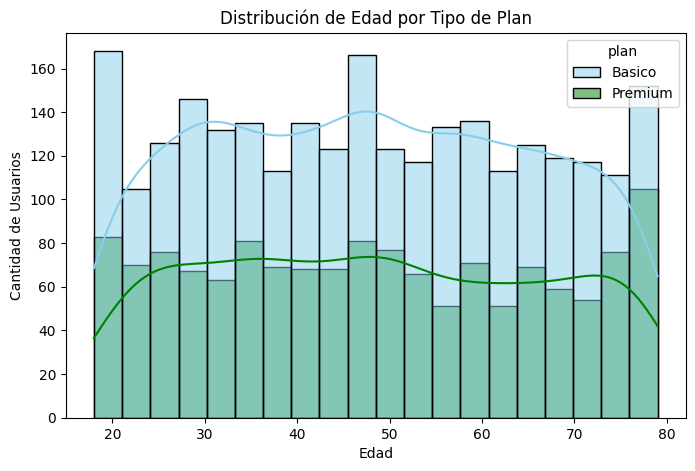

In [30]:
# Histograma para visualizar la edad (age)
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], kde=True, bins=20)
plt.title('Distribución de Edad por Tipo de Plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()

💡Insights: 
- Se distribuye de manera uniforme en todas las edades, la proporción de jóvenes, adultos y personas mayores se mantiene estable.
- El plan básico tiene un volumen bastante mayor que el premium en todas las edades, entonces la edad no es un factor determinante para el plan.

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Histograma de edad completo (`hue='plan'`, paleta, título y etiquetas) y un insight claro: distribución pareja y Básico con más usuarios en todas las edades.
</div>

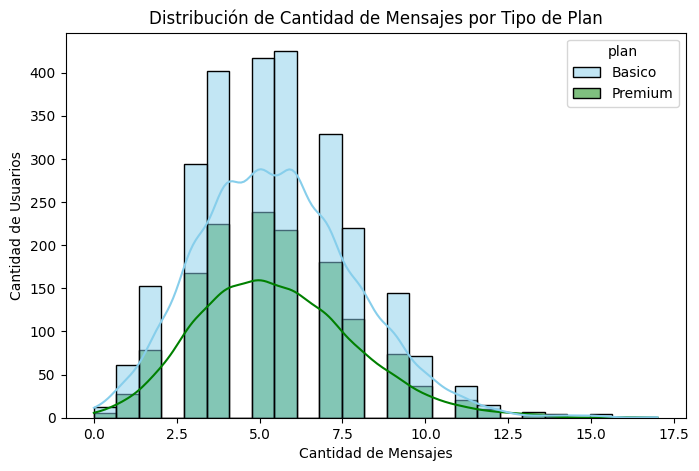

In [31]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], kde=True, bins=25)
plt.title('Distribución de Cantidad de Mensajes por Tipo de Plan')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Cantidad de Usuarios')
plt.show()

💡Insights: 
- Los datos se distribuyen en forma de la Gampana de Gauss, con un leve sesgo a la derecha, alcanzando el punto máximo de usuarios entre los 5 y 6 mensajes tanto para basico como para premium. El plan básico también cuenta con más usuarios en comparación con premium.

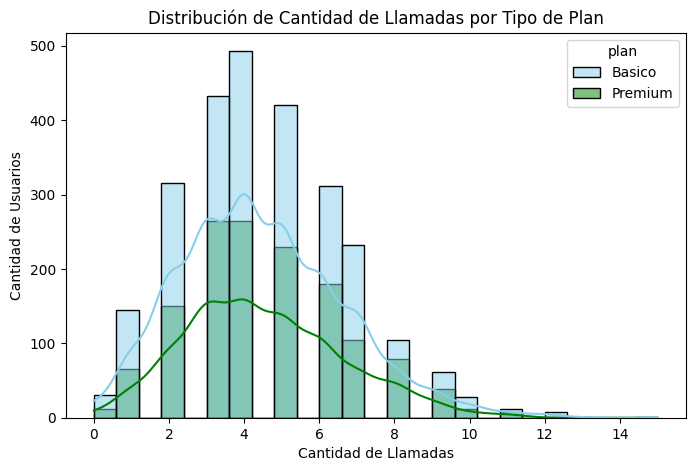

In [32]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], kde=True, bins=25)
plt.title('Distribución de Cantidad de Llamadas por Tipo de Plan')
plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Cantidad de Usuarios')
plt.show()

💡Insights: 
- La gráfica muestra una distribución unimodal, igualmente sesgada hacia la derecha don la mayoría de usuarios realizan 4 llamadas. Conforme aumenta el número de llamadas, la frecuencia disminuye progresivamente, existiendo una cola larga hacia la derecha donde muy pocos usuarios realizan más de 9 o 10 llamadas. El plan básico es contratado por más usuarios, aunque la diferencia va disminuyendo conforme más llamadas realizan los usuarios.

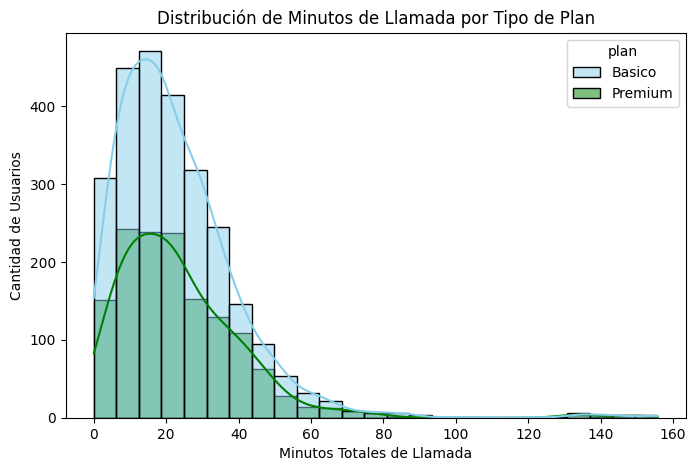

In [33]:
# Histograma para visualizar la cant_minutos_llamada
col_minutos = 'cant_minutos_llamada' if 'cant_minutos_llamada' in user_profile.columns else 'total_minutos_llamada'

plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x=col_minutos, hue='plan', palette=['skyblue', 'green'], kde=True, bins=25)
plt.title('Distribución de Minutos de Llamada por Tipo de Plan')
plt.xlabel('Minutos Totales de Llamada')
plt.ylabel('Cantidad de Usuarios')
plt.show()

💡Insights: 
- Esta gráfica muestra una distribución fuertemente sesgada a la derecha donde se puede observar que la mayoría de clientes realiza menos de 30 minutos totales de llamada. Conforme aumentan los minutos, la frecuencia decae rápidamente hacia una cola larga. Incluso se aprecian valores extremos aislados por encima de los 120–140 minutos. El plan Básico concentra un mayor número absoluto de usuarios a lo largo de toda la distribución en comparación con el plan Premium.

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Los cuatro histogramas cumplen la consigna y los insights describen forma de la distribución y comparación entre planes. Tips: (1) para respaldar "comportamiento similar entre planes" agrega `user_profile.groupby('plan')[['cant_mensajes','cant_llamadas','cant_minutos_llamada']].mean()`; (2) en el insight de llamadas dices que "la diferencia entre planes va disminuyendo": en realidad la forma de ambos planes es la misma y Premium solo tiene menos usuarios (35% de la base), así que las barras más altas muestran la diferencia más grande en valor absoluto.
</div>

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

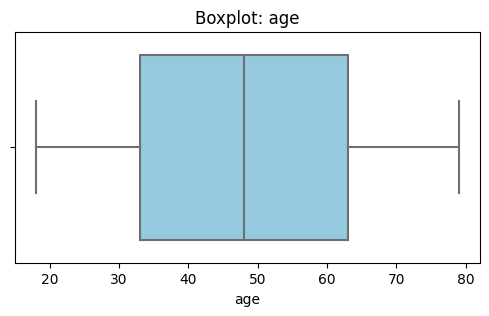

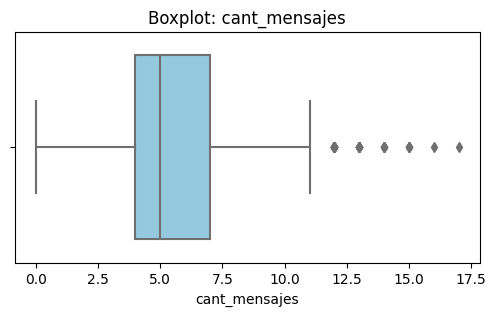

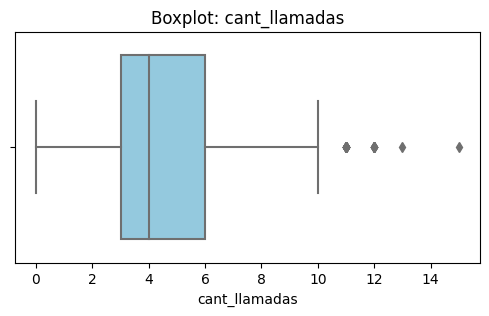

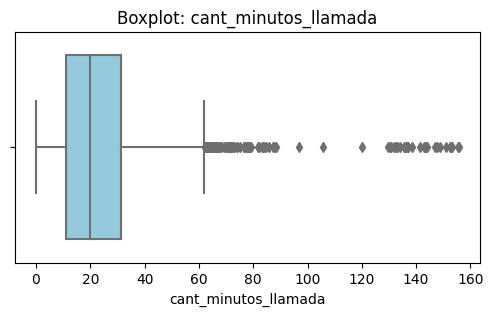

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(6, 3))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Correcto: un `for` genera los 4 boxplots con título dinámico.
</div>

💡Insights: 
- Age: No presenta outliers, va de 18 a 79 sin puntos fuera de los bigotes.
- cant_mensajes: Sí presenta outliers superiores, el valor máximo es de 17 llamadas.
- cant_llamadas: Sí presenta outliers superiores, el valor máximo es de 15 mensajes.
- cant_minutos_llamada: Sí presenta outliers superiores, el valor máximo es de ~156 minutos.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Respondes correctamente quién tiene outliers, pero conviene decir más: por ejemplo los valores máximos que se ven (17 mensajes, 15 llamadas, ~156 minutos) y que `age` va de 18 a 79 sin puntos fuera de los bigotes.
</div>

In [35]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr
    conteo_outliers = (user_profile[col] > limite_superior).sum()
    print(f"{col}: Límite superior = {limite_superior:.2f} | Outliers detectados = {conteo_outliers}")

cant_mensajes: Límite superior = 11.50 | Outliers detectados = 46
cant_llamadas: Límite superior = 10.50 | Outliers detectados = 30
cant_minutos_llamada: Límite superior = 61.87 | Outliers detectados = 109


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

IQR correcto: calculas solo el límite superior (los outliers están solo a la derecha) y cuentas los outliers: 46 en mensajes (1.15%), 30 en llamadas y 109 en minutos. Tip: imprime también Q1, Q3 e IQR para mostrar el cálculo completo.
</div>

In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡Insights: 

- cant_mensajes: Mantener. El método IQR establece un límite superior de 11.5 mensajes. Se identificaron 46 outliers con un valor máximo de 17 mensajes. Estos registros representan un uso intensivo pero completamente factible en un entorno real de mensajería.
- cant_llamadas:Mantener. El cálculo IQR arroja un límite superior de 10.5 llamadas. Se detectaron 30 outliers, alcanzando un máximo de 15 llamadas. Corresponden a clientes con mayor frecuencia de comunicación (heavy users) y no a errores técnicos de captura.
- cant_minutos_llamada: Mantener. Presenta un límite superior de 61.87 minutos y un total de 109 outliers, con un máximo acumulado de 155.7 minutos. Es importante destacar que esta variable mide la suma total de minutos de todo el período por usuario (no una sola llamada). Un consumo acumulado de hasta ~2.6 horas a lo largo del período analizado es un patrón de uso humano enteramente plausible que no debe eliminarse de la base.


<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Decisión de mantener los outliers bien encaminada, pero cuida la interpretación: `cant_minutos_llamada` es el **total de minutos de todo el periodo por usuario** (máximo 155.7), no una sola llamada (la llamada más larga es de 120 minutos). Reescribe la justificación citando los números: límite superior (11.5 / 10.5 / 61.87), máximo (17 / 15 / 155.7) y cuántos outliers hay (46 / 30 / 109).
</div>

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]

elecciones = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(condiciones, elecciones, default='Alto uso')

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Lógica correcta (umbrales `< 5` y `< 10` con `np.select`). Como rellenaste con 0 al usuario sin eventos, queda en 'Bajo uso'. Tip: agrega `user_profile['grupo_uso'].value_counts()` para ver (y citar en el insight) el tamaño de cada grupo: deberías obtener Uso medio 2,943, Bajo uso 779 y Alto uso 278.
</div>

In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:

# Crear columna grupo_edad
condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

categorias_edad = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(condiciones_edad, categorias_edad, default='Adulto Mayor')


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Lógica correcta (`< 30`, `< 60`, 'Adulto Mayor' por defecto). Tip: agrega `user_profile['grupo_edad'].value_counts()` para citar las cifras exactas (Adulto 2,018, Adulto Mayor 1,222, Joven 760).
</div>

In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

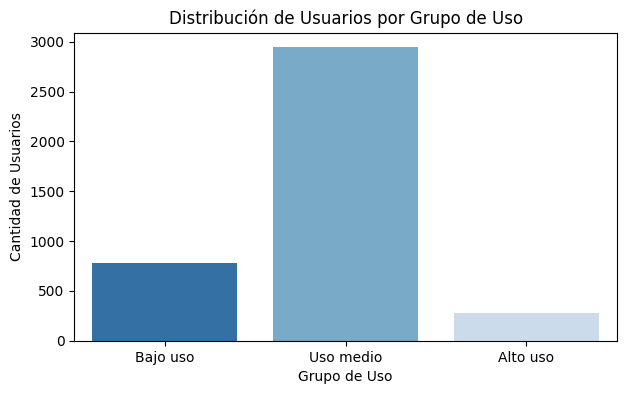

In [41]:
# Visualización de los segmentos por uso
plt.figure(figsize=(7, 4))
sns.countplot(
    data=user_profile, 
    x='grupo_uso', 
    order=['Bajo uso', 'Uso medio', 'Alto uso'], 
    palette='Blues_r'
)
plt.title('Distribución de Usuarios por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Usuarios')
plt.show()

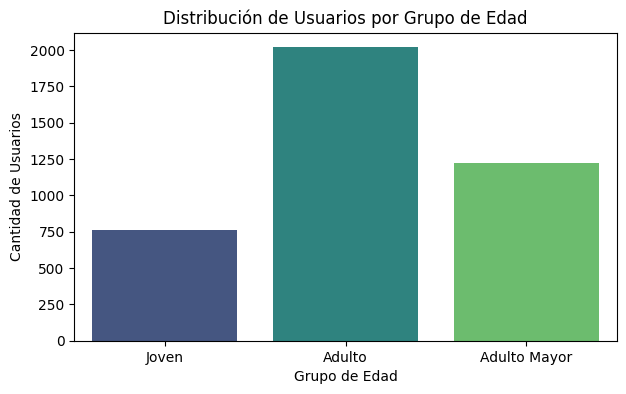

In [42]:
# Visualización de los segmentos por edad
plt.figure(figsize=(7, 4))
sns.countplot(
    data=user_profile, 
    x='grupo_edad', 
    order=['Joven', 'Adulto', 'Adulto Mayor'], 
    palette='viridis'
)
plt.title('Distribución de Usuarios por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Los dos countplots están completos: título, etiquetas y orden lógico de las categorías.
</div>

In [43]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')

# Rellenar con 0 a los usuarios que no registraron actividad
cols_metricas = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_metricas] = user_profile[cols_metricas].fillna(0)

In [44]:
# Comparación de consumo promedio por plan
promedios_plan = user_profile.groupby('plan')[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].mean()
print("Promedios de consumo por plan:")
display(promedios_plan)

# Usuarios que realmente superan el límite del plan Básico (100 minutos)
superan_100_min = (user_profile['cant_minutos_llamada'] > 100).sum()
pct_superan_100 = (superan_100_min / len(user_profile)) * 100
print(f"Usuarios con más de 100 minutos: {superan_100_min} ({pct_superan_100:.2f}%)")

# Usuarios que superan los 100 mensajes del plan Básico
superan_100_sms = (user_profile['cant_mensajes'] > 100).sum()
print(f"Usuarios con más de 100 mensajes: {superan_100_sms}")

Promedios de consumo por plan:


,cant_mensajes,cant_llamadas,cant_minutos_llamada
plan,,,
Basico,5.525626,4.454721,22.896609
Premium,5.518149,4.518149,24.077011


Usuarios con más de 100 minutos: 31 (0.78%)
Usuarios con más de 100 mensajes: 0


In [45]:
# 1. Conteo por grupo de edad
print("Distribución por grupo de edad:")
display(user_profile['grupo_edad'].value_counts())

# 2. Promedios de consumo por grupo de edad (para respaldar la recomendación)
print("\nPromedio de consumo por grupo de edad:")
display(user_profile.groupby('grupo_edad')[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].mean())

Distribución por grupo de edad:


KeyError: 'grupo_edad'


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

###### Análisis ejecutivo


⚠️ **Problemas detectados en los datos**
- Se detectaron valores erróneos de -999 en 55 filas (1.4%) en users['age']. Estos correspondían a valores atípicos imposibles.
- En users ['city'] se observan 96 filas (2.4%) de valores como '?' y 469 filas (11.7%) de nuos originales. En total son 565 registros faltantes de los 4,000 (14.1%)
- En users['reg_date'] se encontraron 40 filas (1%) con el año 2026, un año futuro e imposible al corte del estudio (2024).
- En users['churn_date'] existen 3,534 valores nulos, pero no representa una falla en la recolección de datos. La fecha de cancelación solo se genera cuando un cliente da de baja el servicio, por lo tanto, la ausencia de valor refleja que el 88.4% de los usuarios siguen activos en la compañía.
- Usage['date'] cuenta con 50 valores nulos (0.125%) que representan una pérdida marginal de marcas de tiempo en el log de eventos transaccionales.
- Usage['duration'] (22,076 valores nulos, 55.2%) y usage['length'] (17,896 valores nulos, 44.7%) constituyen nulos estructurales condicionados al tipo de servicio MAR. Los 22,076 nulos en duration (55.2%) corresponden a los registros donde type == 'text', ya que un mensaje SMS no tiene duración en minutos. Los 17,896 nulos en length (44.7%) coinciden con los registros donde type == 'call', dado que una llamada de voz no posee longitud en caracteres de texto.


🔍 **Segmentos por Edad**
Al respaldar el análisis, se demuestra numéricamente que la edad no condiciona el nivel de uso:
  - Los **Adultos** (2,018 usuarios) promedian **5.55 mensajes, 4.48 llamadas y 22.99 minutos**.
  - Los **Adultos Mayores** (1,222 usuarios) promedian **5.49 mensajes, 4.50 llamadas y 23.58 minutos**.
  - Los **Jóvenes** (760 usuarios) promedian **5.52 mensajes, 4.43 llamadas y 23.75 minutos**.
  Al tener un comportamiento prácticamente idéntico entre segmentos, se concluye que ConnectaTel no debe diseñar ofertas comerciales divididas por rangos de edad, sino basarse estrictamente en la intensidad real de tráfico (volumen de llamadas y mensajes) de cada cliente.

📊 **Segmentos por Nivel de Uso**
'Uso medio' agrupa a 2,943 clientes (73.6%), 'Bajo uso' a 779 clientes (19.5%) y 'Alto uso' a 278 clientes (6.9%).
Al analizar el consumo promedio mediante groupby('plan').mean(), se comprueba que los clientes de ambos planes tienen un uso prácticamente igual: el plan Básico promedia 5.53 mensajes, 4.45 llamadas y 22.90 minutos, mientras que el Premium registra 5.52 mensajes, 4.52 llamadas y 24.08 minutos. Dado que el plan Básico ya incluye 100 minutos y 100 mensajes, el 99.22% de toda la cartera no supera los límites incluidos en el paquete de menor costo (solo 31 usuarios rebasan los 100 minutos y ninguno rebasa los 100 mensajes).


💡 **Recomendaciones**
- Al comparar los promedios de consumo, los usuarios de ambos planes presentan un uso prácticamente idéntico. El riesgo es que Los clientes Premium pagan más del doble ($25 USD vs. $12 USD) por un límite mucho más amplio (600 minutos y 500 mensajes) que no utilizan.

<div class="alert alert-block alert-danger">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

**Bloqueante: el insight tiene cifras incorrectas y afirmaciones sin respaldo.** Compáralo con tus propios outputs:

**Problemas de los datos**
- `city`: dices "565 filas con el valor '?' (alrededor del 11.3% de un dataset de usuarios de **5,000** registros)". Los datos correctos son: `?` = **96 filas (2.4%)**, nulos originales = 469 (11.7%), y en total **565 faltantes = 14.1% de 4,000 usuarios**.
- `age`: falta cuantificar: **55 filas (1.4%)** con `-999`.
- Faltan problemas que la consigna pide cuantificar: `churn_date` (3,534 nulos, 88.4%, estructural: usuarios activos), `usage.date` (50 nulos, 0.125%) y `duration`/`length` (22,076 = 55.2% y 17,896 = 44.7%, nulos estructurales según `type`).

**Segmentos por edad**
- "Joven ... 750 usuarios": son **760** (19.0%). Adulto: **2,018** (50.5%). Adulto mayor: **1,222** (30.6%); y el umbral es **≥ 60**, no "> 60".
- "La edad ... no condiciona el consumo de llamadas o mensajes": **no hay ningún cálculo** que lo respalde. Calcúlalo antes de afirmarlo: `user_profile.groupby('grupo_edad')[['cant_mensajes','cant_llamadas','cant_minutos_llamada']].mean()` y escribe lo que salga.

**Segmentos por uso**
- Uso medio "75%" y Alto uso "6%": con tus datos son **2,943 (73.6%)** y **278 (6.95%, ≈ 7%)**; Bajo uso 779 (19.5%).
- "medias de 3 a 5 llamadas y 4 a 6 mensajes mensuales": no hay cálculo y las métricas son del **periodo completo**, no mensuales (evita "al mes").

**Texto incompleto:** hay una línea "➡️ Esto sugiere que ..." sin terminar. Complétala (por ejemplo, con la conclusión sobre los segmentos más valiosos y por qué) o bórrala.

**Recomendaciones**
- "Los usuarios Premium consumen casi la misma cantidad de minutos y SMS que los Básicos": puede ser cierto, pero en el notebook no hay cálculo por plan. Agrega `user_profile.groupby('plan')[[...]].mean()`.
- "Plan de llamadas ilimitadas para outliers (> 60–100 min)": antes de proponerlo, revisa cuántos de esos 109 usuarios realmente superan lo incluido en el plan Básico (100 minutos): `(user_profile['cant_minutos_llamada'] > 100).sum()`. Recuerda que el máximo de todo el periodo es 155.7 minutos.
- Evita basar recomendaciones en variables que el dataset no tiene (datos móviles, roaming): apóyate en llamadas, mensajes, plan y edad.
</div>

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

https://github.com/alitopena-del/sprint_7_data_analysis

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Advertencia (no bloqueante): (1) la celda de arriba conserva el placeholder `LINK a tu repo aquí`: bórrala o reemplázala. (2) Este link está en una celda de **código**, así que al ejecutarla da `SyntaxError`. Conviértela a **Markdown** y usa el formato `[Ver repositorio en GitHub](https://github.com/alitopena-del/sprint7-final-project)`. (3) No pude verificar desde aquí que el repositorio sea público ni que tenga el `README.md`; compruébalo abriendo el link en una ventana de incógnito.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

**Veredicto: ❌ NO APROBADO por dos puntos**

| Criterio | Estado |
|---|---|
| Archivo correcto (`users_latam.csv`) | ✅ Correcto |
| Diagnóstico de nulos (2.1) | ⚠️ Cifras correctas; acciones contradicen 3.2 |
| **Diagnóstico de sentinels (2.2): `age` (-999), `city` (?), máximos** | ❌ **Pendiente (bloqueante)** |
| Diagnóstico de fechas (2.3) | ✅ Correcto |
| Limpieza (`age`, `city`, `reg_date`) y MAR | ✅ Correctos |
| Agregación y `merge` (`left` + `fillna(0)`) | ✅ Correctos |
| Histogramas con insights, boxplots e IQR | ✅ Correctos (tips de redacción) |
| Segmentaciones y countplots | ✅ Correctos |
| **Insight ejecutivo con cifras exactas y respaldo** | ❌ **Pendiente (bloqueante)** |
| Ejecución de principio a fin | ⚠️ Hacer Restart & Run All |
| Celda de GitHub | ⚠️ Advertencia |

Estás muy cerca: el análisis de fondo es sólido. Para aprobar, corrige:
1. El **diagnóstico oficial de 2.2** (incluye `age` = -999 con 55 filas / 1.4%, `city` = `?` con 96 filas / 2.4% más 469 nulos, y los máximos de `duration` y `length`).
2. El **insight ejecutivo** con los números de tus propios outputs (96 `?`, 565 faltantes = 14.1% de 4,000; 760 / 2,018 / 1,222 por edad; 2,943 / 779 / 278 por uso), y respalda con un `groupby` lo que digas sobre edad y planes.

Al terminar haz **Kernel → Restart Kernel & Run All Cells** y verifica que los números van seguidos y sin errores. Recuerda corregir también la celda de GitHub. ¡Ánimo! 💪
</div>